# Notebook 4 — Dark-condition simulation: night travel under train headlights

**Workshop path:** [NB0](00_flight_precheck.ipynb) · [NB1](01_sample_data_generation.ipynb) · [NB2](02_batch_dataset_generation.ipynb) · [NB3](03_training_and_evaluation.ipynb) · **this notebook** (Labels4Rail railway data).

Railway perception has to work at night, but most labelled frames are daytime or dusk. This notebook turns **one real L4R_NLB cab frame** into a night frame that is lit only by the train's own headlights — and treats *physical correctness* as the thing to get right.

**The physical setup matters.** The camera sits 2.8 m above the rails inside the cab; the headlights sit on the train front about 1 m above the rails, **below and ahead of the camera**. So at night:

- the lamps themselves are never in frame;
- the brightest area is the track and ballast in the lower centre of the frame;
- light falls off quickly with distance (inverse square, at a grazing angle on the ground);
- the lower parts of nearby objects catch more light than their tops; the sky is near-black.

```text
 real frame + calibration + annotations
   → GEOMETRY        calibrated rail plane  +  Depth Anything aligned to it (metric 3D)
   → PHYSICS PRIOR   headlight irradiance map → physically based night render
   → PROMPT DEV      ablate → measure (physics metrics + VLM critic) → slot rewrite → seed check
   → SELECT + LABEL  switch boxes carried over, each flagged visible / dark at night
```

The **physics prior** is the key idea: it is a geometry-exact reference for *where light should be*, so every generated candidate can be checked against it instead of by eye.

### What "good" means here

| Signal | Question | Source |
|---|---|---|
| `beam_corr` | Is the light where lamps below the camera would put it? | candidate log-luminance vs physics irradiance on ground pixels |
| `phantom_light` | Did the editor invent light sources (visible headlights, streetlights, flares)? | bright pixels where irradiance ≈ 0 |
| `lit_structure` | Are rails / sleepers / switches kept where it is lit? | illumination-invariant detail correlation, weighted by irradiance |
| `clipped_lit` | Is the beam blown out to white (detail lost)? | saturated pixels inside the beam |
| `mean_luma` | Is it actually night? | mean sRGB luma (target ≈ 0.12) |
| VLM critic | Does a strong vision model believe it, under the same physical rubric? | `judge.model_id` via the Vector proxy |

`selection_score` combines them (weights are a workshop choice, not a calibrated quality model).

---
## 0 — Setup

In [1]:
import os


os.environ.setdefault("HF_HUB_DISABLE_XET", "1")

import gc
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from aieng.syn_data.image.bootstrap import bootstrap_project_root
from aieng.syn_data.image.config import load_config, load_env
from aieng.syn_data.image.data.frames import frame_source_for
from aieng.syn_data.image.generate import night
from aieng.syn_data.image.workflow import night as wf
from aieng.syn_data.image.workflow.store import RunStore, studio_root
from PIL import Image


PROJECT_ROOT = bootstrap_project_root()
load_env(PROJECT_ROOT)

DATASET = "l4r_nlb"
HARDWARE = "gpu_l4"
SOURCE_ID = "nlb_fall_000419"  # one frame first — any annotated L4R frame works
REFINE_ROUNDS = 2  # VLM-guided prompt rewrites after the ablation
SEED_OFFSETS = (1, 2)  # extra seeds for the robustness check (seed 0 already ran)
WORK_SIZE = wf.DEFAULT_WORK_SIZE  # (768, 432): Klein's 768-px input cap; all analysis on this grid
USE_VLM = True  # set False to rank on physics metrics only (no API calls)

cfg = load_config(
    start=PROJECT_ROOT,
    overrides=[f"dataset_name={DATASET}", f"hardware={HARDWARE}"],
)
store = RunStore(studio_root(cfg))  # shared with the Synthetic Data Studio app
out_dir = Path(cfg.paths.outputs_dir) / "night" / SOURCE_ID
out_dir.mkdir(parents=True, exist_ok=True)
print(f"Dataset={cfg.dataset_name}  Hardware={cfg.hardware.name}  Judge={cfg.judge.model_id}")
print("outputs →", out_dir)


def show_row(images, titles, *, width=6.5):
    """Show images side by side."""
    fig, axes = plt.subplots(1, len(images), figsize=(width * len(images), width * 0.6))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img, cmap="inferno" if np.ndim(img) == 2 else None)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def free(*names):
    """Drop notebook globals that hold GPU models."""
    for name in names:
        obj = globals().pop(name, None)
        if obj is not None and hasattr(obj, "unload"):
            obj.unload()
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

/home/coder/synthetic-data-bootcamp/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset=l4r_nlb  Hardware=gpu_l4  Judge=gemini-3-flash-preview
outputs → /home/coder/synthetic-data-bootcamp/implementations/edge_case_image_generation/outputs/l4r_nlb/night/nlb_fall_000419


### Load one frame, its annotation, track mask, switch labels, and the camera calibration

`frame_source_for(cfg)` reads the Labels4Rail season folder directly, so any annotated frame works; switch boxes are normalised from the annotation's switch marks (same rules as `scripts/prepare_l4r_samples.py`).

RailCamera(width=1920, height=1080, fx=2000.0, fy=2000.0, cx=959.5, cy=539.5, pitch_down_deg=2.5, yaw_deg=1.4, height_m=2.8)
tags: {'additional_attributes': [], 'environment': ['rural'], 'light': ['auto_bright_dark', 'uniform', 'natural'], 'time_of_day': ['twilight'], 'track_layout': ['curve'], 'weather': ['cloudy']}
3 switch boxes; 6 annotated tracks


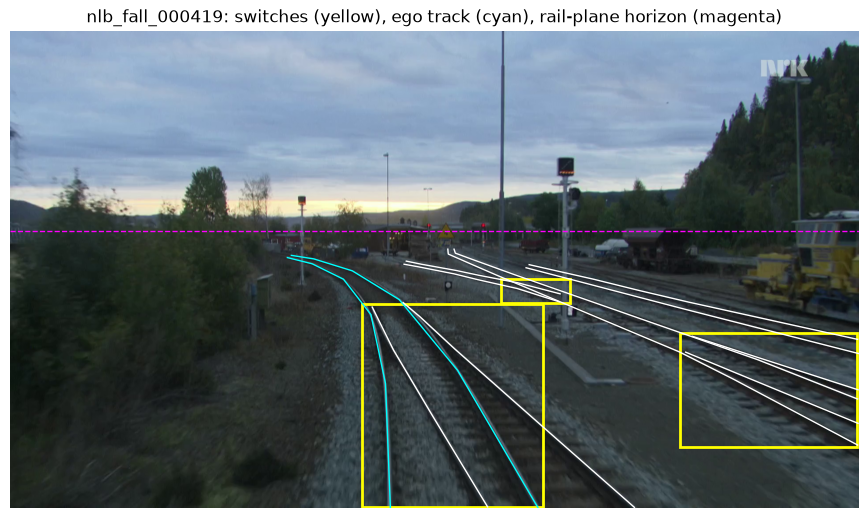

In [2]:
frame = frame_source_for(cfg).get(SOURCE_ID)
print(f"{frame.frame_id}: capabilities={sorted(frame.capabilities)}")
image = frame.load_image()
annotation = frame.annotation
switch_boxes = list(frame.boxes)
camera = night.RailCamera.from_opencv_yaml(frame.camera_path)

print(camera)
print("tags:", annotation["tag groups"])
print(f"{len(switch_boxes)} switch boxes;", f"{len(night.track_polylines(annotation))} annotated tracks")

fig, ax = plt.subplots(figsize=(11, 6.2))
ax.imshow(image)
for box in switch_boxes:
    x1, y1, x2, y2 = box["bbox_xyxy"]
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="yellow", lw=2))
for track in night.track_polylines(annotation):
    colour = "cyan" if track["position"] == "ego" else "white"
    for side in ("left", "right"):
        ax.plot(track[side][:, 0], track[side][:, 1], color=colour, lw=1)
ax.axhline(camera.horizon_row, color="magenta", ls="--", lw=1)
ax.set_title(f"{SOURCE_ID}: switches (yellow), ego track (cyan), rail-plane horizon (magenta)")
ax.axis("off")
plt.show()

---
## 1 — Geometry: trust the calibration, but verify it

L4R ships one `camera.yaml` per season (f = 2000 px, pitch, yaw, camera height). We model a pinhole camera above a flat rail plane, so every pixel below the horizon maps to a point on the ground.

**Check:** the annotated ego rails must be ~1.5 m apart (1435 mm gauge + rail-head width) **at every distance**. A wrong pitch, height or sign convention makes the gauge drift with distance. (The YAML stores pitch/yaw with the opposite sign to our frame; on 71 straight annotated tracks the negated yaw keeps the track straight — 0.05 m lateral drift over 30 m vs 0.75 m otherwise.)

In [3]:
gauge = night.rail_gauge_check(annotation, camera)
print(f"{'row':>5} {'distance':>9} {'gauge':>7} {'centre x':>9}")
for r in gauge:
    print(f"{r['row']:5.0f} {r['distance_m']:8.1f}m {r['gauge_m']:6.3f}m {r['centre_x_m']:+8.2f}m")
gauges = np.array([r["gauge_m"] for r in gauge])
if gauges.size == 0:
    print("No ego track in this frame — lamps default to the camera centre line.")
elif np.all(np.abs(gauges - 1.5) < 0.15):
    print(f"Calibration OK: gauge {gauges.mean():.3f} ± {gauges.std():.3f} m across {gauges.size} distances")
else:
    print("WARNING: gauge drifts — calibration does not fit this frame; physics prior is unreliable.")

  row  distance   gauge  centre x
 1050      9.3m  1.491m    +0.50m
  950     11.1m  1.483m    +0.43m
  850     14.0m  1.472m    +0.31m
  750     18.7m  1.489m    +0.07m
  680     24.5m  1.419m    -0.36m
  630     31.5m  1.441m    -0.92m
Calibration OK: gauge 1.466 ± 0.027 m across 6 distances


### Metric 3D from monocular depth, anchored on the rails

Depth Anything gives *relative* inverse depth (unknown scale and shift). On the **track-mask pixels the rail plane gives exact metric depth**, so we fit `disparity ≈ a / Z + b` there (trimmed least squares) and get metric depth for trees, poles and buildings too. Monocular depth gives the sky a finite distance, so sky comes from the ADE20K SegFormer instead.

`wf.analyze_frame` does all of this and caches the geometry under `outputs/l4r_nlb/studio/cache/` — the Synthetic Data Studio app reuses the same cache, so re-runs skip the depth and segmentation models.

Loading weights: 100%|██████████| 644/644 [00:00<00:00, 21350.46it/s]


Depth alignment on 28477 rail pixels: a=7.79, b=0.060, rmse=0.0059 (disparity units)
ground 45%  objects 22%  sky 33%


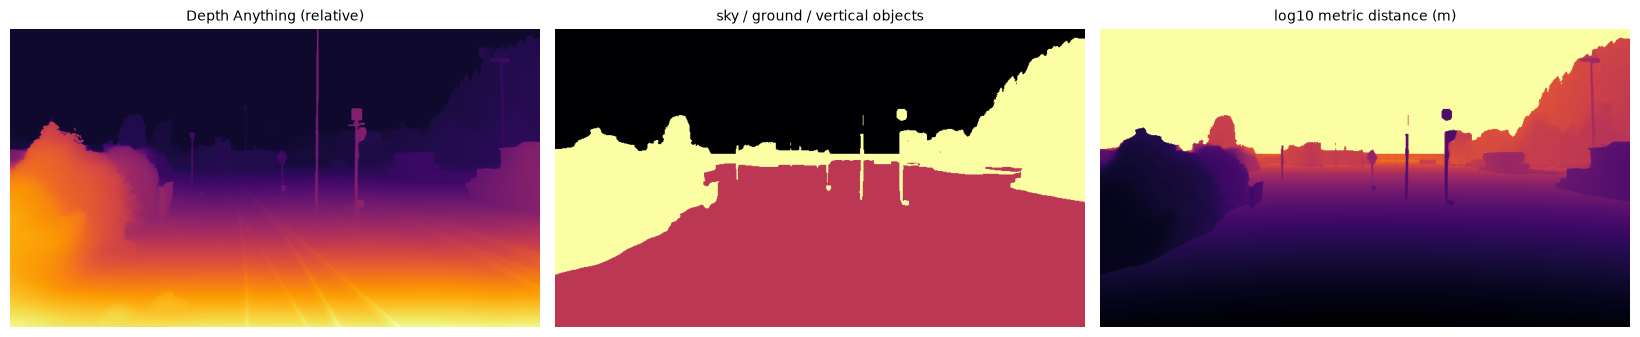

In [4]:
analysis = wf.analyze_frame(
    frame,
    work_size=WORK_SIZE,
    load_models=lambda: wf.load_conditioning_models(cfg),  # only on a cache miss
    cache=wf.GeometryCache(studio_root(cfg) / "cache"),
    model_key=wf.model_key(cfg),
)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

geometry = analysis.geometry
fit = geometry.depth_fit
print(
    f"Depth alignment on {fit['n']:.0f} rail pixels: a={fit['a']:.2f}, b={fit['b']:.3f}, "
    f"rmse={fit['rmse']:.4f} (disparity units)",
)
print(
    f"ground {geometry.ground.mean():.0%}  objects {(~geometry.ground & ~geometry.sky).mean():.0%}  "
    f"sky {geometry.sky.mean():.0%}",
)

distance = np.linalg.norm(geometry.points, axis=-1)
classes = np.where(geometry.sky, 0, np.where(geometry.ground, 1, 2))
show_row(
    [analysis.disparity, classes, np.log10(np.nan_to_num(distance, nan=1e3))],
    ["Depth Anything (relative)", "sky / ground / vertical objects", "log10 metric distance (m)"],
    width=5.5,
)

---
## 2 — Physics prior: where would the headlights put light?

Two lamps on the train front, below the camera. For each 3D point **P** with surface normal **n** (up for ground, facing the train for vertical objects):

$$E(P) = \sum_{\text{lamps}} I(\theta_h, \theta_v)\,\frac{\max(0,\; \mathbf{n}\cdot \hat{\mathbf{l}})}{r^2}$$

with a Gaussian beam lobe (wide horizontally, sharp cut-off upward, broader downward) plus a weak wide spill. `E` is normalised so the track centre 15 m ahead = 1. Occlusion shadows are **not** modelled — a known limitation.

The render relights the linear-light frame (an albedo proxy at dusk) with warm lamp light, a faint blue ambient, rail-head glints from the annotated rails, a near-black sky, and sensor noise.

lamps (x, y-down, z) m: [[-0.22, 1.8, 2.0], [1.08, 1.8, 2.0]]
beam reach (track lit at ≥5% of the 15 m level): 41 m


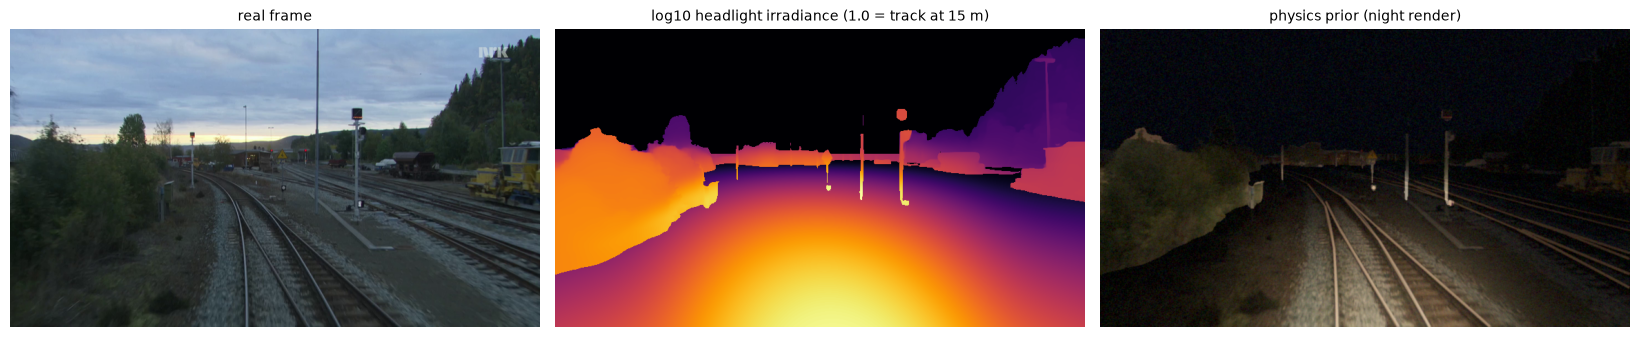

{'mean_luma': 0.1, 'dark_fraction': 0.601, 'beam_corr': 0.844, 'lit_structure': 0.639, 'phantom_light': 0.0, 'clipped_lit': 0.0}
  switch box irradiance=1.19  visible_at_night=True
  switch box irradiance=0.03  visible_at_night=False
  switch box irradiance=0.23  visible_at_night=False


In [5]:
rig, look, irradiance, prior = analysis.rig, analysis.look, analysis.irradiance, analysis.prior
work_image = image.resize(WORK_SIZE, Image.Resampling.LANCZOS)
prior.save(out_dir / "physics_prior.png")

print("lamps (x, y-down, z) m:", np.round(rig.lamp_positions(camera), 2).tolist())
print(f"beam reach (track lit at ≥5% of the 15 m level): {rig.beam_reach_m(camera):.0f} m")
show_row(
    [work_image, np.log10(irradiance + 1e-3), prior],
    ["real frame", "log10 headlight irradiance (1.0 = track at 15 m)", "physics prior (night render)"],
    width=5.5,
)
prior_metrics = night.night_metrics(
    image,
    prior,
    irradiance,
    geometry,
    boxes=switch_boxes,
    box_scale=analysis.box_scale,
)
print({k: round(v, 3) for k, v in prior_metrics.items() if k != "boxes"})
for b in prior_metrics["boxes"]:
    print(f"  switch box irradiance={b['irradiance']:.2f}  visible_at_night={b['visible']}")

The prior is physically consistent by construction but looks synthetic (flat shading, no light scattering, no occlusion). A generative editor can supply realism — the risk is that it also invents light sources or moves geometry. That trade-off is what the prompt has to manage.

---
## 3 — Prompt development

How we develop the prompt:

1. **Ground it in measured facts** — environment / weather / layout tags from the annotation, the switch count from the labels, and the **beam reach computed from the physics model**, not guessed.
2. **Structure it in slots** (`task, scene, darkness, light_source, beam, falloff, unlit, camera, preserve`) so we can change one thing at a time and diff versions.
3. **Ablate** a few principled variants under a fixed seed.
4. **Measure** each with physics metrics + a VLM critic that is given the same physical setup.
5. **Refine** with the VLM rewriting *slots* from the review history — `task` and `preserve` are locked so the geometry contract can't be optimised away.
6. **Check seeds** — a prompt that wins on one seed may just be lucky.

The ablation:

| Variant | Input | Idea |
|---|---|---|
| `A_naive` | photo | what a user types first |
| `B_named_source` | photo | physically accurate text that *names* the headlights |
| `C_effect_only` | photo | same physics, but describes only **where light lands** |
| `D_hybrid_prior` | physics prior | effect-only prompt that *refines* the physics render |

> **Hypothesis behind C/D:** few-step editors draw the nouns they read. "Headlights … out of frame" tends to produce *visible* headlights — often an oncoming train at the vanishing point. Describing the effect avoids naming an object to draw.

In [6]:
facts = analysis.facts
print("scene facts:", facts)

presets = wf.prompt_presets(facts)
candidates = {
    "A_naive": presets["naive"],
    "B_named_source": presets["named_source"],
    "C_effect_only": presets["effect_only"],
    "D_hybrid_prior": presets["hybrid_prior"],
}
for name, cand in candidates.items():
    print(f"\n[{name}] ({cand['input']})\n{cand['prompt']}")

scene facts: {'environment': ['rural'], 'weather': ['cloudy'], 'track_layout': ['curve'], 'n_tracks': 6, 'n_switches': 3, 'camera_height_m': 2.8, 'lamp_height_m': 1.0, 'beam_reach_m': 41}

[A_naive] (photo)
Make this photo a night scene.

[B_named_source] (photo)
Relight this forward-facing train cab photo as the same scene on a dark night. A rural Norwegian railway, curve track, 6 tracks with 3 railway switches, cloudy sky. It is a moonless night under thick cloud; the only real light is the train's headlights. Two warm halogen headlights are mounted low on the train front, about 1 m above the rails and below the camera, so the lamps are out of frame. The pool lights the ballast and sleepers at the bottom centre of the frame, and the steel rail heads glint where lit. The light fades quickly with distance; beyond about 41 m the track disappears into darkness and the far end of the line is completely black. Trees, poles, buildings and the sky outside the pool fall to near-black; the sky

### Generate the ablation (FLUX.2 Klein instruct, fixed seed)

Klein runs through the same `MethodComparer.run_method("instruct", …)` path as NB1/NB2; the prompt is passed as an in-memory anomaly config. First call loads the model (~1 min); each edit then takes ~20 s on an L4.

/home/coder/synthetic-data-bootcamp/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


→ A_naive


100%|██████████| 4/4 [00:33<00:00,  8.46s/it]


→ B_named_source


100%|██████████| 4/4 [00:09<00:00,  2.38s/it]


→ C_effect_only


100%|██████████| 4/4 [00:08<00:00,  2.23s/it]


→ D_hybrid_prior


100%|██████████| 4/4 [00:08<00:00,  2.13s/it]


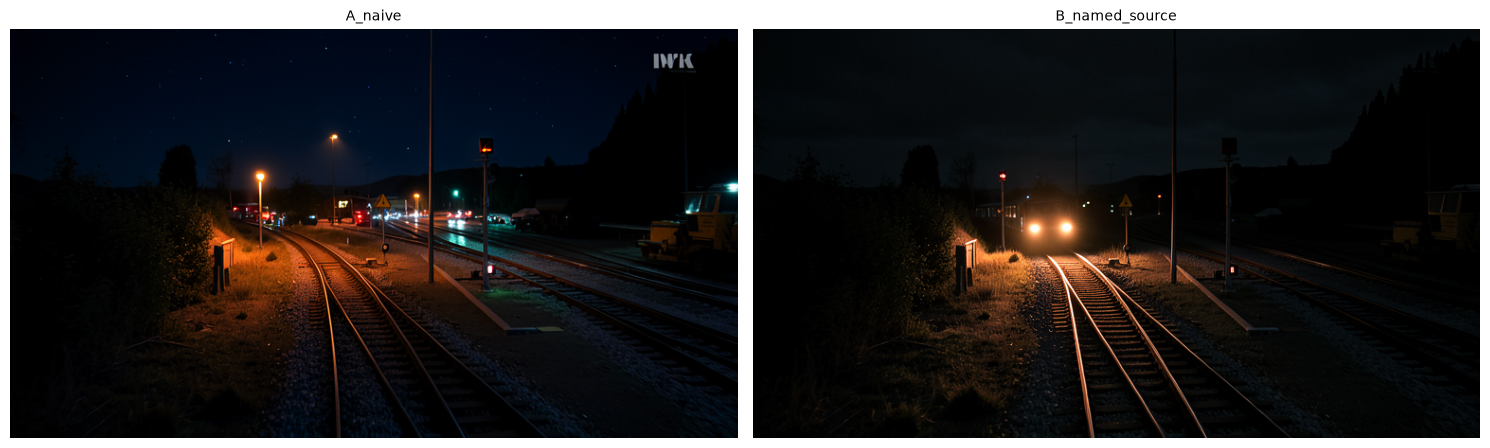

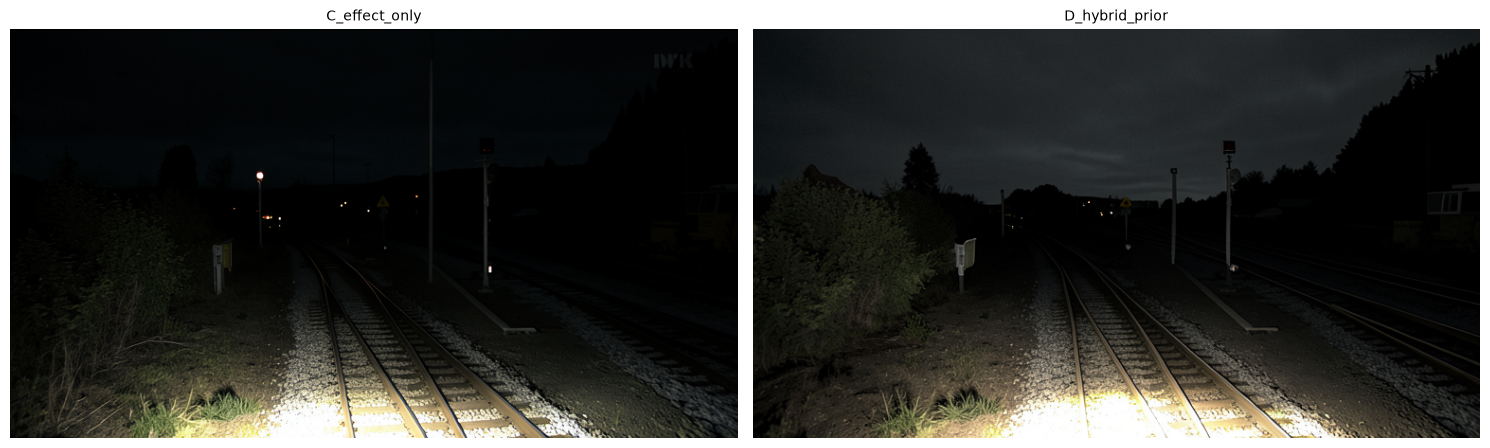

In [7]:
from aieng.syn_data.image.compare_methods import MethodComparer


comparer = MethodComparer.from_config(cfg)
inputs = {"photo": image, "prior": prior}
run_id = store.create_run(
    frame,
    kind="notebook",
    settings={"hardware": HARDWARE, "work_size": list(WORK_SIZE), "notebook": "04_dark_condition_simulation"},
    analysis=analysis.meta(),
)
print("studio run:", run_id)


def generate(input_key: str, prompt: str, *, seed_offset: int = 0) -> Image.Image:
    """Run one Klein instruct edit and return it on the analysis grid."""
    return wf.generate_image(
        comparer,
        cfg.generation,
        inputs[input_key],
        prompt,
        work_size=WORK_SIZE,
        seed_offset=seed_offset,
    )


runs, images = [], {}
for name, cand in candidates.items():
    print(f"→ {name}", flush=True)
    img = generate(cand["input"], cand["prompt"])
    img.save(out_dir / f"{name}.png")
    run = wf.Candidate(label=name, input=cand["input"], prompt=cand["prompt"], slots=cand["slots"])
    runs.append(run)
    images[run.candidate_id] = img

show_row([images[r.candidate_id] for r in runs[:2]], [r.label for r in runs[:2]], width=7.5)
show_row([images[r.candidate_id] for r in runs[2:]], [r.label for r in runs[2:]], width=7.5)

### Score: physics metrics + VLM critic

The critic sees the real frame and the candidate and scores six criteria plus `overall`, and returns the single biggest problem and a concrete prompt fix. Unparsable replies are recorded as **unscored** (never as invented default scores). If any candidate lacks a VLM score, ranking falls back to physics metrics for all candidates so scores stay comparable. `gate` applies the accept thresholds used by the app's batch mode (`wf.DEFAULT_GATES`). Every scored candidate is also saved to a studio run, so you can review and export it in the app.

In [ ]:
from aieng.syn_data.image.judge.night_critic import rewrite_prompt


VLM_KW = {
    "model": str(cfg.judge.model_id),
    "api_base_url": cfg.judge.get("api_base_url"),
    "provider": cfg.judge.get("api_provider"),
}
vlm_state = {"ok": USE_VLM}  # flips to False after the first API failure
_critic = wf.make_critic(cfg)


def critic(original, candidate):
    """Call the VLM critic until the first failure, then stop calling the API."""
    if not vlm_state["ok"]:
        raise RuntimeError("VLM disabled after an earlier failure")
    try:
        return _critic(original, candidate)
    except Exception as exc:
        print(f"VLM critic unavailable ({type(exc).__name__}: {exc}); physics metrics only.")
        vlm_state["ok"] = False
        raise


def score(run: wf.Candidate) -> wf.Candidate:
    """Score a candidate and save it to the shared studio run."""
    wf.score_candidate(
        run,
        images[run.candidate_id],
        frame,
        analysis,
        critic=critic if vlm_state["ok"] else None,
    )
    if run.critique and run.critique.get("error") and vlm_state["ok"]:
        print(f"  {run.label}: VLM reply unparsable ({run.critique['error']}) — unscored")
    store.add_candidate(run_id, run, images[run.candidate_id])
    return run


def report(pool: list[wf.Candidate]) -> None:
    """Print a ranked table of candidates."""
    header = f"{'run':24s} {'rank':>5} {'phys':>5} {'vlm':>4} {'beam':>5} {'phantom':>8} {'struct':>6} {'clip':>5} {'luma':>5}"
    print(header)
    print("-" * len(header))
    for r in sorted(pool, key=lambda r: -wf.rank_key(r, pool)):
        m = r.metrics
        vlm = f"{r.vlm_overall:4.1f}" if r.vlm_overall is not None else "  - "
        beam = m["beam_corr"] if m["beam_corr"] is not None else float("nan")
        struct = m["lit_structure"] if m["lit_structure"] is not None else float("nan")
        print(
            f"{r.label:24s} {wf.rank_key(r, pool):5.3f} {r.physics_score:5.3f} {vlm} "
            f"{beam:5.2f} {m['phantom_light']:8.5f} {struct:6.2f} "
            f"{m['clipped_lit']:5.2f} {m['mean_luma']:5.3f}  gate={'pass' if r.gate['passed'] else 'fail'}",
        )
    for r in pool:
        if r.critique and r.critique.get("critique"):
            print(f"\n[{r.label}] {r.critique['critique']}\n   fix → {r.critique['prompt_fix']}")


for run in runs:
    score(run)
report(runs)

---
## 4 — Refine: VLM rewrites the slots from the review history

Start from the best slot-structured candidate. Each round the VLM sees the real frame, the best image so far, the current slots and the full history (metrics + critiques), and returns rewritten slots. Locked slots (`task`, `preserve`) are restored if changed; malformed replies stop the loop. Each rewrite is generated with the **same seed** and input, so differences come from the prompt.

In [ ]:
slot_runs = [r for r in runs if r.slots]
best = max(slot_runs, key=lambda r: wf.rank_key(r, runs))
print(f"Refining from {best.label} (input={best.input})")
history = [wf.history_entry(r) for r in runs]

for round_idx in range(1, REFINE_ROUNDS + 1):
    if not vlm_state["ok"]:
        print("VLM unavailable — skipping refinement (ablation winner is kept).")
        break
    rewrite = rewrite_prompt(best.slots, history, work_image, images[best.candidate_id], **VLM_KW)
    if rewrite.error:
        print(f"Round {round_idx}: rewrite rejected ({rewrite.error}); stopping.")
        break
    print(f"\nRound {round_idx} changed {rewrite.changed}: {rewrite.rationale}")
    for key in rewrite.changed:
        print(f"  - {key}: {best.slots[key]}\n  + {key}: {rewrite.slots[key]}")
    prompt = night.compose_prompt(rewrite.slots)
    label = f"R{round_idx}_from_{best.label}"
    run = wf.Candidate(label=label, input=best.input, prompt=prompt, slots=rewrite.slots)
    images[run.candidate_id] = generate(best.input, prompt)
    images[run.candidate_id].save(out_dir / f"{label}.png")
    runs.append(score(run))
    history.append(wf.history_entry(run))
    if wf.rank_key(run, runs) > wf.rank_key(best, runs):
        best = run

report(runs)
refined = [r for r in runs if r.label.startswith("R")] or [best]
show_row([images[r.candidate_id] for r in refined], [r.label for r in refined], width=7.5)

---
## 5 — Seed robustness, then select

Re-run the selected prompt with other seeds. A large spread means the prompt is fragile; in a batch run every seed would face the same filter, so the final frame is the best-scoring seed of the **selected prompt**.

In [ ]:
seed_runs = [best]
for offset in SEED_OFFSETS:
    label = f"{best.label}_seed{offset}"
    run = wf.Candidate(label=label, input=best.input, prompt=best.prompt, slots=best.slots, seed_offset=offset)
    images[run.candidate_id] = generate(best.input, best.prompt, seed_offset=offset)
    images[run.candidate_id].save(out_dir / f"{label}.png")
    seed_runs.append(score(run))
runs.extend(seed_runs[1:])

seed_scores = np.array([wf.rank_key(r, seed_runs) for r in seed_runs])
print(
    f"selected prompt over {len(seed_runs)} seeds: score {seed_scores.mean():.3f} ± {seed_scores.std():.3f} "
    f"(min {seed_scores.min():.3f})",
)
report(seed_runs)
final = max(seed_runs, key=lambda r: wf.rank_key(r, seed_runs))
show_row(
    [work_image, prior, images[final.candidate_id]],
    ["real frame", "physics prior", f"selected: {final.label}"],
    width=6,
)
free("comparer")

---
## 6 — Labels at night

The relight is global, so switch boxes keep their coordinates — **if** the editor preserved geometry. But a switch outside the beam may be invisible at night, and a box around pure darkness is a bad training label. Each box is flagged `visible_at_night` when it receives meaningful light (irradiance ≥ 0.15) **and** its local structure still matches the real frame (correlation ≥ 0.3).

In [ ]:
night_boxes = night.scale_boxes(final.metrics["boxes"], *analysis.box_scale)
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.imshow(images[final.candidate_id])
for box in night_boxes:
    x1, y1, x2, y2 = box["bbox_xyxy"]
    colour = "lime" if box["visible"] else "red"
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=colour, lw=2))
    structure = "-" if box["structure"] is None else f"{box['structure']:.2f}"
    ax.text(x1, y1 - 3, f"E={box['irradiance']:.2f} s={structure}", color=colour, fontsize=8)
ax.set_title("switch labels at night: visible (green) / too dark or changed (red)")
ax.axis("off")
plt.show()

final_path = out_dir / f"scene_{SOURCE_ID}_night.png"
images[final.candidate_id].save(final_path)
night_labels = {
    final_path.name: [
        {
            "label": b["label"],
            "bbox_xyxy": [round(v, 2) for v in b["bbox_xyxy"]],
            "visible_at_night": b["visible"],
            "irradiance": round(b["irradiance"], 3),
            "structure": None if b["structure"] is None else round(b["structure"], 3),
        }
        for b in night_boxes
    ],
}
(out_dir / "labels_night.json").write_text(json.dumps(night_labels, indent=2) + "\n")
print(f"{sum(b['visible'] for b in night_boxes)}/{len(night_boxes)} switch boxes visible at night")

### Save the prompt-development log

In [ ]:
log = {
    "source_id": SOURCE_ID,
    "studio_run_id": run_id,
    **analysis.meta(),
    "physics_prior_metrics": {k: v for k, v in prior_metrics.items() if k != "boxes"},
    "runs": [{**r.to_dict(), "file": f"{r.label}.png"} for r in runs],
    "selected": {
        "label": final.label,
        "candidate_id": final.candidate_id,
        "prompt": final.prompt,
        "slots": final.slots,
        "input": final.input,
        "file": final_path.name,
        "seed_scores": seed_scores.round(4).tolist(),
    },
}
(out_dir / "prompt_development.json").write_text(
    json.dumps(wf.to_jsonable(log), indent=2, allow_nan=False) + "\n",
)
print("saved:", sorted(p.name for p in out_dir.iterdir()))
print(f"All candidates are also in the studio run {run_id} (Review/Runs pages of synthetic_data_studio).")
print("\nSelected prompt:\n" + final.prompt)

---
## Takeaways and next steps

- **Physics first, then generation.** The calibrated rail plane + rail-anchored monocular depth turn "lamps below the camera" into a per-pixel irradiance map — a reference that makes night realism *measurable*.
- **Describe effects, not sources.** Naming headlights invites the editor to draw them; the phantom-light metric catches it.
- **Structured prompts make iteration auditable.** Slot diffs + locked `preserve` keep geometry intact while the VLM optimises wording.
- **Labels need a visibility check.** Relighting preserves box coordinates, but not necessarily visibility.

Next:

1. **Scale out:** loop this notebook's steps over all 16 prepared frames with the selected prompt; keep the per-frame physics checks as accept gates.
2. **Vary conditions:** lamp colour (halogen / LED), rain or fog scattering in the beam, a faint moon — as `variations` in `configs/datasets/l4r_nlb/generation/anomalies/night_headlights.yaml`.
3. **Validate against real darkness:** L4R_NLB winter frames include genuinely dark Norwegian conditions (`light: dark`, `time_of_day: night`) — compare synthetic and real night frames with the same metrics.
4. **Downstream test:** train a switch detector on day-only vs day + synthetic night, evaluate on real dark frames (NB3 pattern).